In [ ]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import databento as db

from scipy.interpolate import griddata

sys.path.append(str(Path.cwd().parent))

from src.black_scholes import black_scholes_price
from src.implied_volatility import Newton_Raphson_iv

client = db.Historical()

In [ ]:
# Authenticate using DATABENTO_API_KEY environment variable
client = db.Historical()

# Test connection
print(client.metadata.list_datasets())

['ARCX.PILLAR', 'BATS.PITCH', 'BATY.PITCH', 'DBEQ.BASIC', 'EDGA.PITCH', 'EDGX.PITCH', 'EPRL.DOM', 'EQUS.MINI', 'EQUS.SUMMARY', 'GLBX.MDP3', 'IEXG.TOPS', 'IFEU.IMPACT', 'IFLL.IMPACT', 'IFUS.IMPACT', 'MEMX.MEMOIR', 'NDEX.IMPACT', 'OCEA.MEMOIR', 'OPRA.PILLAR', 'XASE.PILLAR', 'XBOS.ITCH', 'XCBF.PITCH', 'XCHI.PILLAR', 'XCIS.TRADESBBO', 'XEEE.EOBI', 'XEUR.EOBI', 'XNAS.BASIC', 'XNAS.ITCH', 'XNYS.PILLAR', 'XPSX.ITCH']


In [ ]:
cost = client.metadata.get_cost(
    dataset="OPRA.PILLAR",
    symbols=["SPY.OPT"],
    stype_in="parent",
    schema="definition",
    start="2026-09-15T00:00:00",
    end="2026-09-16T00:00:00",
)

print(cost)

0.021960586309


In [ ]:
data = client.timeseries.get_range(
    dataset="OPRA.PILLAR",
    symbols=["SPY.OPT"],
    stype_in="parent",
    schema="definition",
    start="2026-09-15T00:00:00",
    end="2026-09-16T00:00:00",
)

df = data.to_df()

print(df.iloc[0].to_json(indent=4))

{
    "ts_event":1789468200642,
    "rtype":19,
    "publisher_id":30,
    "instrument_id":1358954497,
    "raw_symbol":"SPY   270115P00565000",
    "security_update_action":"A",
    "instrument_class":"P",
    "min_price_increment":null,
    "display_factor":null,
    "expiration":1799971200000,
    "activation":null,
    "high_limit_price":null,
    "low_limit_price":null,
    "max_price_variation":null,
    "trading_reference_price":null,
    "unit_of_measure_qty":null,
    "min_price_increment_amount":null,
    "price_ratio":null,
    "inst_attrib_value":2147483647,
    "underlying_id":11,
    "raw_instrument_id":1358954497,
    "market_depth_implied":2147483647,
    "market_depth":2147483647,
    "market_segment_id":4294967295,
    "max_trade_vol":4294967295,
    "min_lot_size":2147483647,
    "min_lot_size_block":2147483647,
    "min_lot_size_round_lot":2147483647,
    "min_trade_vol":4294967295,
    "contract_multiplier":2147483647,
    "decay_quantity":2147483647,
    "original

In [ ]:
options = df[["instrument_id","raw_symbol","instrument_class","strike_price","expiration","underlying"]].copy()

In [ ]:
options

,instrument_id,raw_symbol,instrument_class,strike_price,expiration,underlying
ts_recv,,,,,,
2026-09-15 10:30:00.642770268+00:00,1358954497,SPY 270115P00565000,P,565.0,2027-01-15 00:00:00+00:00,SPY
2026-09-15 10:30:00.642786146+00:00,1358954498,SPY 270115P00515000,P,515.0,2027-01-15 00:00:00+00:00,SPY
2026-09-15 10:30:00.652584694+00:00,1358954499,SPY 270115P00500000,P,500.0,2027-01-15 00:00:00+00:00,SPY
2026-09-15 10:30:00.652594518+00:00,1358954500,SPY 270115P00520000,P,520.0,2027-01-15 00:00:00+00:00,SPY
2026-09-15 10:30:00.653371076+00:00,1358954501,SPY 270115P00775000,P,775.0,2027-01-15 00:00:00+00:00,SPY
...,...,...,...,...,...,...
2026-09-15 12:00:00.804497243+00:00,1342206478,SPY 260928C00930000,C,930.0,2026-09-28 00:00:00+00:00,SPY
2026-09-15 12:00:00.804497243+00:00,1342206479,SPY 260928C00935000,C,935.0,2026-09-28 00:00:00+00:00,SPY
2026-09-15 12:00:00.804497243+00:00,1342206480,SPY 260928C00945000,C,945.0,2026-09-28 00:00:00+00:00,SPY


In [ ]:
expiries = (options["expiration"].drop_duplicates().sort_values())

print(f"Number of expiries: {len(expiries)}")
print(expiries.to_string(index=False))

Number of expiries: 34
ts_recv
2026-09-15 00:00:00+00:00
2026-09-16 00:00:00+00:00
2026-09-17 00:00:00+00:00
2026-09-18 00:00:00+00:00
2026-09-21 00:00:00+00:00
2026-09-22 00:00:00+00:00
2026-09-23 00:00:00+00:00
2026-09-24 00:00:00+00:00
2026-09-25 00:00:00+00:00
2026-09-28 00:00:00+00:00
2026-09-29 00:00:00+00:00
2026-09-30 00:00:00+00:00
2026-10-02 00:00:00+00:00
2026-10-09 00:00:00+00:00
2026-10-16 00:00:00+00:00
2026-10-23 00:00:00+00:00
2026-10-30 00:00:00+00:00
2026-11-20 00:00:00+00:00
2026-11-30 00:00:00+00:00
2026-12-18 00:00:00+00:00
2026-12-31 00:00:00+00:00
2027-01-15 00:00:00+00:00
2027-01-29 00:00:00+00:00
2027-02-26 00:00:00+00:00
2027-03-19 00:00:00+00:00
2027-03-31 00:00:00+00:00
2027-06-17 00:00:00+00:00
2027-06-30 00:00:00+00:00
2027-09-17 00:00:00+00:00
2027-12-17 00:00:00+00:00
2028-01-21 00:00:00+00:00
2028-06-16 00:00:00+00:00
2028-12-15 00:00:00+00:00
2029-01-19 00:00:00+00:00


In [ ]:
selected_expiries = pd.to_datetime([
    "2026-09-18",
    "2026-10-16",
    "2026-11-20",
    "2026-12-18",
    "2027-03-19"
], utc=True)

surface_options = options[
    options["expiration"].isin(selected_expiries)
].copy()

print(f"Contracts remaining: {len(surface_options)}")

print(
    surface_options.groupby(
        ["expiration", "instrument_class"]
    ).size()
)

Contracts remaining: 2080
expiration                 instrument_class
2026-09-18 00:00:00+00:00  C                   321
                           P                   321
2026-10-16 00:00:00+00:00  C                   221
                           P                   221
2026-11-20 00:00:00+00:00  C                   141
                           P                   141
2026-12-18 00:00:00+00:00  C                   158
                           P                   158
2027-03-19 00:00:00+00:00  C                   199
                           P                   199
dtype: int64


In [ ]:
cost = client.metadata.get_cost(
    dataset="DBEQ.BASIC",
    symbols=["SPY"],
    schema="ohlcv-1m",
    start="2026-09-15T19:30:00",
    end="2026-09-15T19:31:00",
)

print(cost)

5.476177e-06


In [ ]:
spy_data = client.timeseries.get_range(
    dataset="DBEQ.BASIC",
    symbols=["SPY"],
    schema="ohlcv-1m",
    start="2026-09-15T19:30:00",
    end="2026-09-15T19:31:00",
)

spy_df = spy_data.to_df()

print(spy_df)

                           rtype  publisher_id  instrument_id     open  \
ts_event                                                                 
2026-09-15 19:30:00+00:00     33            39          15144  756.930   
2026-09-15 19:30:00+00:00     33            40          15144  756.990   
2026-09-15 19:30:00+00:00     33            41          15144  756.955   

                              high      low    close  volume symbol  
ts_event                                                             
2026-09-15 19:30:00+00:00  757.020  756.930  757.020     364    SPY  
2026-09-15 19:30:00+00:00  756.990  756.990  756.990      40    SPY  
2026-09-15 19:30:00+00:00  757.025  756.935  756.975    3048    SPY  


In [ ]:
S0 = np.average(
    spy_df["close"],
    weights=spy_df["volume"]
)

print(f"SPY spot price: ${S0:.4f}")

SPY spot price: $756.9799


In [ ]:
surface_options["moneyness"] = (
    surface_options["strike_price"] / S0
)

surface_options[
    ["raw_symbol", "instrument_class", "strike_price", "expiration", "moneyness"]
].head(10)

,raw_symbol,instrument_class,strike_price,expiration,moneyness
ts_recv,,,,,
2026-09-15 10:30:00.763675036+00:00,SPY 270319P00350000,P,350.0,2027-03-19 00:00:00+00:00,0.462364
2026-09-15 10:30:00.773697510+00:00,SPY 270319P00440000,P,440.0,2027-03-19 00:00:00+00:00,0.581257
2026-09-15 10:30:00.773708460+00:00,SPY 270319P00650000,P,650.0,2027-03-19 00:00:00+00:00,0.858675
2026-09-15 10:30:00.783571748+00:00,SPY 270319P00390000,P,390.0,2027-03-19 00:00:00+00:00,0.515205
2026-09-15 10:30:00.783582276+00:00,SPY 270319P00590000,P,590.0,2027-03-19 00:00:00+00:00,0.779413
2026-09-15 10:30:00.783727356+00:00,SPY 270319P00765000,P,765.0,2027-03-19 00:00:00+00:00,1.010595
2026-09-15 10:30:00.793595171+00:00,SPY 270319P00875000,P,875.0,2027-03-19 00:00:00+00:00,1.155909
2026-09-15 10:30:00.793606134+00:00,SPY 270319P00705000,P,705.0,2027-03-19 00:00:00+00:00,0.931332
2026-09-15 10:30:00.793750711+00:00,SPY 270319P00425000,P,425.0,2027-03-19 00:00:00+00:00,0.561442


In [ ]:
surface_options = surface_options[
    (surface_options["moneyness"] >= 0.80) &
    (surface_options["moneyness"] <= 1.20)
].copy()

print(f"Contracts remaining: {len(surface_options)}")

print(
    surface_options.groupby(
        ["expiration", "instrument_class"]
    ).size()
)

Contracts remaining: 1112
expiration                 instrument_class
2026-09-18 00:00:00+00:00  C                   236
                           P                   236
2026-10-16 00:00:00+00:00  C                   140
                           P                   140
2026-11-20 00:00:00+00:00  C                    60
                           P                    60
2026-12-18 00:00:00+00:00  C                    60
                           P                    60
2027-03-19 00:00:00+00:00  C                    60
                           P                    60
dtype: int64


In [ ]:
symbols = surface_options["raw_symbol"].tolist()

cost = client.metadata.get_cost(
    dataset="OPRA.PILLAR",
    symbols=symbols,
    stype_in="raw_symbol",
    schema="cbbo-1m",
    start="2026-09-15T19:30:00",
    end="2026-09-15T19:31:00",
)

print(f"Number of symbols: {len(symbols)}")
print(f"Estimated cost: ${cost:.6f}")

Number of symbols: 1112
Estimated cost: $0.001526


In [ ]:
quote_data = client.timeseries.get_range(
    dataset="OPRA.PILLAR",
    symbols=symbols,
    stype_in="raw_symbol",
    schema="cbbo-1m",
    start="2026-09-15T19:30:00",
    end="2026-09-15T19:31:00",
)

quotes_df = quote_data.to_df()

print(f"Rows returned: {len(quotes_df)}")
print(quotes_df.head())
print(quotes_df.columns.tolist())

Rows returned: 969
                                                     ts_event  rtype  \
ts_recv                                                                
2026-09-15 19:30:00+00:00 2026-09-15 14:47:06.659801491+00:00    193   
2026-09-15 19:30:00+00:00 2026-09-15 17:39:06.019381108+00:00    193   
2026-09-15 19:30:00+00:00 2026-09-15 14:22:08.234466959+00:00    193   
2026-09-15 19:30:00+00:00 2026-09-15 15:09:35.816853588+00:00    193   
2026-09-15 19:30:00+00:00 2026-09-15 19:25:33.031662052+00:00    193   

                           publisher_id  instrument_id side  price  size  \
ts_recv                                                                    
2026-09-15 19:30:00+00:00            30     1325400522    N   7.32     1   
2026-09-15 19:30:00+00:00            30     1325411457    N   1.57     1   
2026-09-15 19:30:00+00:00            30     1325404134    N   6.42     1   
2026-09-15 19:30:00+00:00            30     1325407784    N  53.10     1   
2026-09-15 19:30:00+

In [ ]:
market_options = quotes_df.merge(
    surface_options[
        [
            "instrument_id",
            "instrument_class",
            "strike_price",
            "expiration",
            "moneyness"
        ]
    ],
    on="instrument_id",
    how="inner"
)

print(f"Rows after merge: {len(market_options)}")

print(
    market_options[
        [
            "symbol",
            "instrument_class",
            "strike_price",
            "expiration",
            "moneyness",
            "bid_px_00",
            "ask_px_00"
        ]
    ].head(10)
)

Rows after merge: 969
                  symbol instrument_class  strike_price  \
0  SPY   270319C00835000                C         835.0   
1  SPY   270319C00885000                C         885.0   
2  SPY   270319C00840000                C         840.0   
3  SPY   270319C00740000                C         740.0   
4  SPY   270319C00850000                C         850.0   
5  SPY   270319C00680000                C         680.0   
6  SPY   270319C00870000                C         870.0   
7  SPY   270319C00845000                C         845.0   
8  SPY   270319C00765000                C         765.0   
9  SPY   270319C00770000                C         770.0   

                 expiration  moneyness  bid_px_00  ask_px_00  
0 2027-03-19 00:00:00+00:00   1.103068       7.16       7.20  
1 2027-03-19 00:00:00+00:00   1.169120       1.55       1.56  
2 2027-03-19 00:00:00+00:00   1.109673       6.21       6.25  
3 2027-03-19 00:00:00+00:00   0.977569      52.82      53.04  
4 2027-03-19 

In [ ]:
market_options["mid_price"] = (market_options["bid_px_00"] + market_options["ask_px_00"]) / 2

In [ ]:
market_options["spread_pct"] = (market_options["ask_px_00"] - market_options["bid_px_00"]) / market_options["mid_price"]

In [ ]:
market_options[["symbol", "bid_px_00", "ask_px_00", "mid_price", "spread_pct"]].head(10)

,symbol,bid_px_00,ask_px_00,mid_price,spread_pct
0,SPY 270319C00835000,7.16,7.20,7.180,0.005571
1,SPY 270319C00885000,1.55,1.56,1.555,0.006431
2,SPY 270319C00840000,6.21,6.25,6.230,0.006421
3,SPY 270319C00740000,52.82,53.04,52.930,0.004156
4,SPY 270319C00850000,4.63,4.67,4.650,0.008602
5,SPY 270319C00680000,99.54,102.54,101.040,0.029691
6,SPY 270319C00870000,2.49,2.52,2.505,0.011976
7,SPY 270319C00845000,5.37,5.41,5.390,0.007421
8,SPY 270319C00765000,35.93,36.10,36.015,0.004720
9,SPY 270319C00770000,32.89,33.05,32.970,0.004853


In [ ]:
market_options["spread_pct"].describe()

count    928.000000
mean       0.060649
std        0.122408
min        0.001652
25%        0.006418
50%        0.023480
75%        0.048780
max        0.666667
Name: spread_pct, dtype: float64

In [ ]:
snapshot_time = pd.Timestamp("2026-09-15 19:30:00", tz="UTC")

In [ ]:
market_options["quote_age_min"] = (
    (snapshot_time - market_options["ts_event"])
    .dt.total_seconds()
    / 60
)

In [ ]:
market_options["quote_age_min"].describe()

count    756.000000
mean      67.815168
std       92.362888
min        0.000710
25%        5.468678
50%       24.444009
75%       96.868469
max      359.993367
Name: quote_age_min, dtype: float64

In [ ]:
for threshold in [1, 5, 10, 30, 60]:
    count = (market_options["quote_age_min"] <= threshold).sum()
    print(f"{threshold:>2} min: {count} quotes")

 1 min: 64 quotes
 5 min: 183 quotes
10 min: 274 quotes
30 min: 421 quotes
60 min: 502 quotes


In [ ]:
fresh_quotes = market_options[
    market_options["quote_age_min"] <= 30
]

print(
    fresh_quotes.groupby(
        ["expiration", "instrument_class"]
    ).size()
)

expiration                 instrument_class
2026-09-18 00:00:00+00:00  C                   57
                           P                   97
2026-10-16 00:00:00+00:00  C                   55
                           P                   79
2026-11-20 00:00:00+00:00  C                   18
                           P                   28
2026-12-18 00:00:00+00:00  C                   28
                           P                   21
2027-03-19 00:00:00+00:00  C                   18
                           P                   20
dtype: int64


In [ ]:
clean_options =  market_options[(market_options["quote_age_min"]<= 30) & (market_options["spread_pct"]<= 0.05)].copy()

In [ ]:
print(f"Clean contracts: {len(clean_options)}")

print(
    clean_options.groupby(
        ["expiration", "instrument_class"]
    ).size()
)

Clean contracts: 351
expiration                 instrument_class
2026-09-18 00:00:00+00:00  C                   35
                           P                   60
2026-10-16 00:00:00+00:00  C                   47
                           P                   79
2026-11-20 00:00:00+00:00  C                   18
                           P                   27
2026-12-18 00:00:00+00:00  C                   26
                           P                   21
2027-03-19 00:00:00+00:00  C                   18
                           P                   20
dtype: int64


In [ ]:
valuation_date = pd.Timestamp("2026-09-15", tz="UTC")

In [ ]:
clean_options["T"] = (clean_options["expiration"] - valuation_date).dt.total_seconds() / (365 * 24 * 60 * 60)

In [ ]:
clean_options[
    ["expiration", "strike_price", "instrument_class", "T"]
].head(10)

,expiration,strike_price,instrument_class,T
4,2027-03-19 00:00:00+00:00,850.0,C,0.506849
5,2027-03-19 00:00:00+00:00,680.0,C,0.506849
7,2027-03-19 00:00:00+00:00,845.0,C,0.506849
8,2027-03-19 00:00:00+00:00,765.0,C,0.506849
9,2027-03-19 00:00:00+00:00,770.0,C,0.506849
11,2027-03-19 00:00:00+00:00,820.0,C,0.506849
19,2027-03-19 00:00:00+00:00,785.0,C,0.506849
26,2027-03-19 00:00:00+00:00,825.0,C,0.506849
27,2027-03-19 00:00:00+00:00,710.0,C,0.506849
29,2027-03-19 00:00:00+00:00,810.0,C,0.506849


In [ ]:
black_scholes_price(100, 100, 1, 0.0364, 0 , 0.20, "call")

np.float64(9.739238679204647)

In [ ]:
q = 0.01
r = 0.0364

In [ ]:
clean_options[
    ["instrument_class", "strike_price", "expiration", 
     "T", "moneyness", "mid_price", "spread_pct", "quote_age_min"]
].assign(
    atm_distance=lambda x: abs(x["moneyness"] - 1)
).sort_values("atm_distance").head(10)

,instrument_class,strike_price,expiration,T,moneyness,mid_price,spread_pct,quote_age_min,atm_distance
841,P,757.0,2026-10-16 00:00:00+00:00,0.084932,1.000027,11.990,0.008340,0.001834,0.000027
494,C,757.0,2026-10-16 00:00:00+00:00,0.084932,1.000027,12.800,0.006250,0.909356,0.000027
194,C,757.0,2026-09-18 00:00:00+00:00,0.008219,1.000027,4.530,0.004415,0.562079,0.000027
736,P,757.0,2026-09-18 00:00:00+00:00,0.008219,1.000027,5.600,0.003571,0.496643,0.000027
385,P,756.0,2026-09-18 00:00:00+00:00,0.008219,0.998705,5.135,0.001947,1.803313,0.001295
411,C,756.0,2026-10-16 00:00:00+00:00,0.084932,0.998705,13.425,0.006704,10.155797,0.001295
949,P,756.0,2026-10-16 00:00:00+00:00,0.084932,0.998705,11.605,0.007755,9.531970,0.001295
224,C,756.0,2026-09-18 00:00:00+00:00,0.008219,0.998705,5.120,0.003906,4.526126,0.001295
560,P,758.0,2026-09-18 00:00:00+00:00,0.008219,1.001348,6.095,0.004922,3.005395,0.001348
114,C,758.0,2026-09-18 00:00:00+00:00,0.008219,1.001348,3.985,0.007528,0.794314,0.001348


In [ ]:
test_option = clean_options[
    (clean_options["instrument_class"] == "C") &
    (clean_options["strike_price"] == 757) &
    (clean_options["expiration"] == pd.Timestamp("2026-10-16", tz="UTC"))
].iloc[0]

test_option

ts_event            2026-09-15 19:29:05.438644011+00:00
rtype                                               193
publisher_id                                         30
instrument_id                                1375732000
side                                                  N
price                                              12.8
size                                                  2
flags                                               192
bid_px_00                                         12.76
ask_px_00                                         12.84
bid_sz_00                                            57
ask_sz_00                                           122
bid_pb_00                                            24
ask_pb_00                                            32
symbol                            SPY   261016C00757000
instrument_class                                      C
strike_price                                      757.0
expiration                    2026-10-16 00:00:0

In [ ]:
Newton_Raphson_iv(S0, test_option["strike_price"], test_option["T"], r, q, test_option["mid_price"], "call")

np.float64(0.1359917931831501)

In [ ]:
def calculate_iv(row):
    if row["instrument_class"] == "C":
        option_type = "call"
    else:
        option_type = "put"
    
    return Newton_Raphson_iv(S0, row["strike_price"], row["T"], r, q, row["mid_price"], option_type)


In [ ]:
clean_options["implied_vol"] = clean_options.apply(calculate_iv,axis=1)

In [ ]:
clean_options["implied_vol"].describe()

count    344.000000
mean       0.184380
std        0.055195
min        0.107689
25%        0.139459
50%        0.174841
75%        0.217628
max        0.361267
Name: implied_vol, dtype: float64

In [ ]:
clean_options["implied_vol"].isna().sum()

np.int64(7)

In [ ]:
clean_options.loc[
    clean_options["implied_vol"].isna(),
    ["instrument_class", "strike_price", "expiration",
     "moneyness", "mid_price", "spread_pct", "quote_age_min"]
]

,instrument_class,strike_price,expiration,moneyness,mid_price,spread_pct,quote_age_min
120,C,655.0,2026-09-18 00:00:00+00:00,0.865281,102.290,0.034021,0.173077
126,C,685.0,2026-09-18 00:00:00+00:00,0.904912,72.735,0.038633,27.544287
203,C,640.0,2026-09-18 00:00:00+00:00,0.845465,117.310,0.030517,17.659242
227,C,650.0,2026-09-18 00:00:00+00:00,0.858675,108.045,0.019529,28.335004
460,P,709.0,2026-09-18 00:00:00+00:00,0.936617,0.215,0.046512,26.286934
814,P,610.0,2026-10-16 00:00:00+00:00,0.805834,0.545,0.018349,9.840773
872,P,615.0,2026-10-16 00:00:00+00:00,0.812439,0.585,0.017094,9.128869


In [ ]:
otm_options = clean_options[((clean_options["instrument_class"]=="P") & (clean_options["strike_price"] < S0) | (clean_options["instrument_class"]=="C") & (clean_options["strike_price"] >= S0))].copy()

In [ ]:
otm_options.shape

(261, 24)

In [ ]:
otm_options["implied_vol"].isna().sum()

np.int64(3)

In [ ]:
vol_surface = otm_options.dropna(subset=["implied_vol"]).copy()

In [ ]:
vol_surface.shape

(258, 24)

In [ ]:
vol_surface.groupby("expiration").size()

expiration
2026-09-18 00:00:00+00:00     55
2026-10-16 00:00:00+00:00    101
2026-11-20 00:00:00+00:00     35
2026-12-18 00:00:00+00:00     38
2027-03-19 00:00:00+00:00     29
dtype: int64

In [ ]:
oct_options = vol_surface[
    vol_surface["expiration"] == pd.Timestamp("2026-10-16", tz="UTC")
].copy()

oct_options.shape

(101, 24)

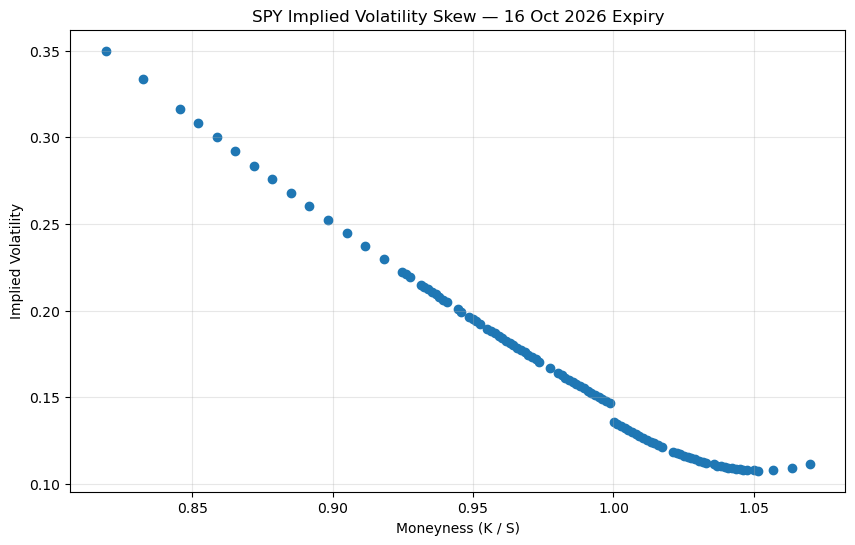

In [ ]:
plt.figure(figsize=(10, 6))

plt.scatter(
    oct_options["moneyness"],
    oct_options["implied_vol"]
)

plt.xlabel("Moneyness (K / S)")
plt.ylabel("Implied Volatility")
plt.title("SPY Implied Volatility Skew — 16 Oct 2026 Expiry")
plt.grid(True, alpha=0.3)

plt.show()

In [ ]:
expiries = sorted(vol_surface["expiration"].unique())

expiries

[Timestamp('2026-09-18 00:00:00+0000', tz='UTC'),
 Timestamp('2026-10-16 00:00:00+0000', tz='UTC'),
 Timestamp('2026-11-20 00:00:00+0000', tz='UTC'),
 Timestamp('2026-12-18 00:00:00+0000', tz='UTC'),
 Timestamp('2027-03-19 00:00:00+0000', tz='UTC')]

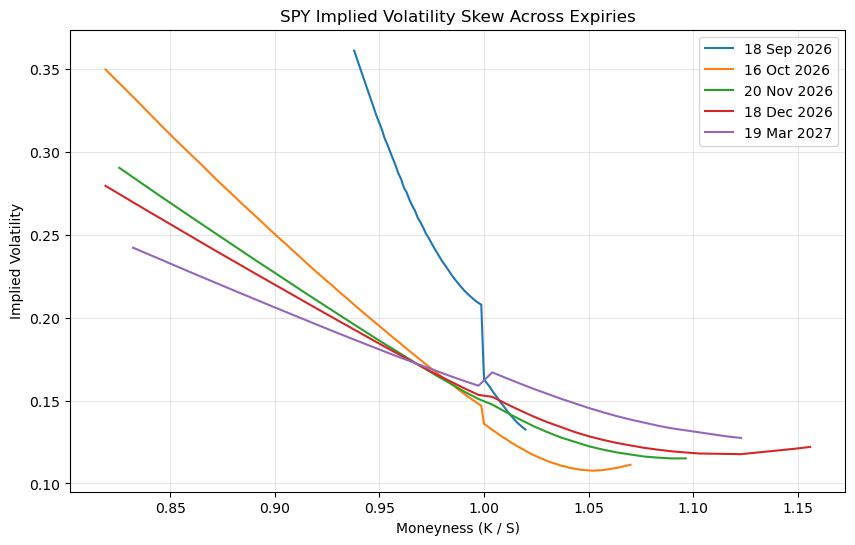

In [ ]:
plt.figure(figsize=(10, 6))

for expiry in expiries:
    expiry_data = vol_surface[
        vol_surface["expiration"] == expiry
    ].sort_values("moneyness")

    plt.plot(
        expiry_data["moneyness"],
        expiry_data["implied_vol"],
        label=pd.Timestamp(expiry).strftime("%d %b %Y")
    )

plt.xlabel("Moneyness (K / S)")
plt.ylabel("Implied Volatility")
plt.title("SPY Implied Volatility Skew Across Expiries")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()
    

In [ ]:
atm_options = clean_options[
    (clean_options["moneyness"] >= 0.98) &
    (clean_options["moneyness"] <= 1.02) &
    (clean_options["implied_vol"].notna())
].copy()

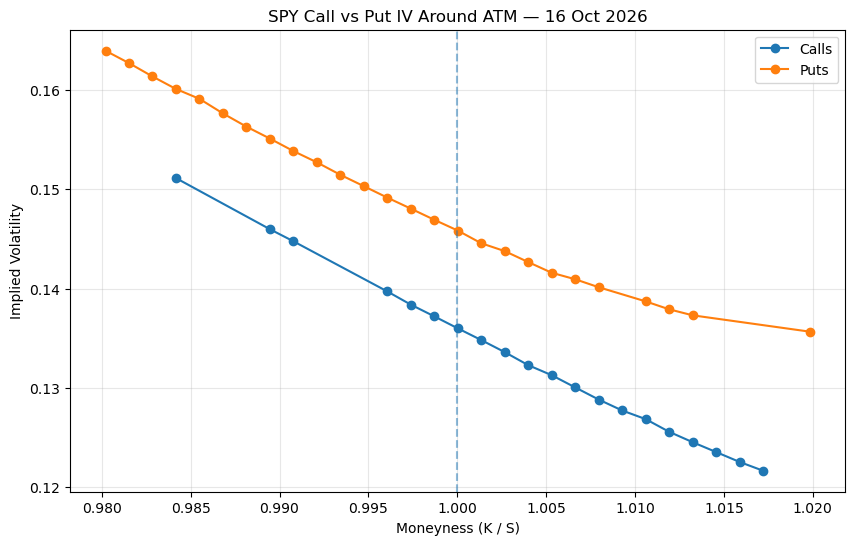

In [ ]:
oct_atm = atm_options[
    atm_options["expiration"] == pd.Timestamp("2026-10-16", tz="UTC")
].copy()

calls = oct_atm[oct_atm["instrument_class"] == "C"].sort_values("moneyness")
puts = oct_atm[oct_atm["instrument_class"] == "P"].sort_values("moneyness")

plt.figure(figsize=(10, 6))

plt.plot(
    calls["moneyness"],
    calls["implied_vol"],
    marker="o",
    label="Calls"
)

plt.plot(
    puts["moneyness"],
    puts["implied_vol"],
    marker="o",
    label="Puts"
)

plt.axvline(1, linestyle="--", alpha=0.5)

plt.xlabel("Moneyness (K / S)")
plt.ylabel("Implied Volatility")
plt.title("SPY Call vs Put IV Around ATM — 16 Oct 2026")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
surface_data = vol_surface[
    ["moneyness", "T", "implied_vol", "expiration"]
].copy()

surface_data.head()

,moneyness,T,implied_vol,expiration
4,1.122883,0.506849,0.127464,2027-03-19 00:00:00+00:00
7,1.116278,0.506849,0.128391,2027-03-19 00:00:00+00:00
8,1.010595,0.506849,0.163645,2027-03-19 00:00:00+00:00
9,1.017200,0.506849,0.160317,2027-03-19 00:00:00+00:00
11,1.083252,0.506849,0.134848,2027-03-19 00:00:00+00:00


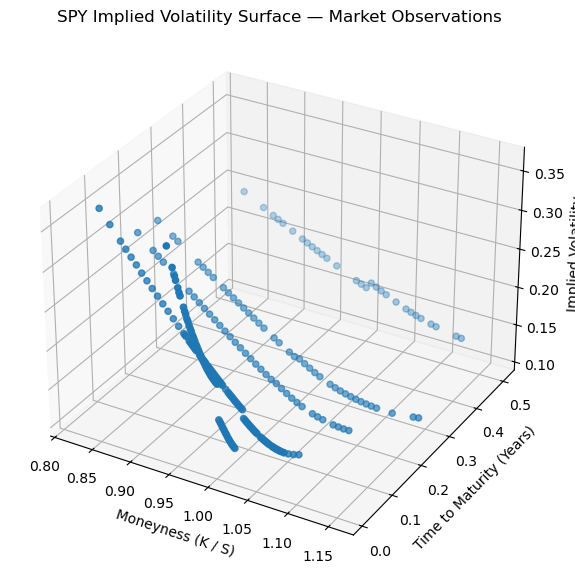

In [ ]:
fig = plt.figure(figsize=(11, 7))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    surface_data["moneyness"],
    surface_data["T"],
    surface_data["implied_vol"]
)

ax.set_xlabel("Moneyness (K / S)")
ax.set_ylabel("Time to Maturity (Years)")
ax.set_zlabel("Implied Volatility")
ax.set_title("SPY Implied Volatility Surface — Market Observations")

plt.show()

In [ ]:


moneyness_grid = np.linspace(
    surface_data["moneyness"].min(),
    surface_data["moneyness"].max(),
    100
)

T_grid = np.linspace(
    surface_data["T"].min(),
    surface_data["T"].max(),
    100
)

M, TT = np.meshgrid(moneyness_grid, T_grid)

In [ ]:
IV_grid = griddata(
    points=(
        surface_data["moneyness"],
        surface_data["T"]
    ),
    values=surface_data["implied_vol"],
    xi=(M, TT),
    method="linear"
)

In [ ]:
IV_grid.shape

(100, 100)

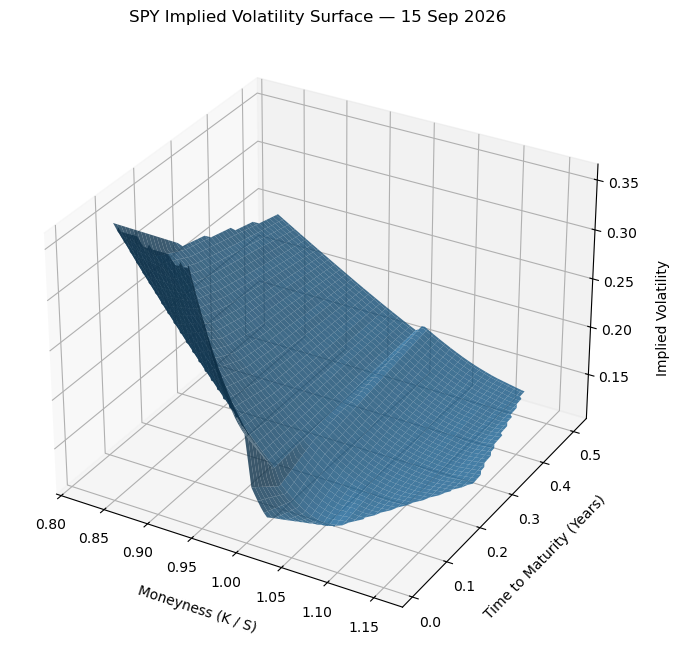

In [ ]:
fig = plt.figure(figsize=(12, 8))

ax = fig.add_subplot(111, projection="3d")

ax.plot_surface(
    M,
    TT,
    IV_grid,
    alpha=0.8
)

ax.set_xlabel("Moneyness (K / S)", labelpad=10)
ax.set_ylabel("Time to Maturity (Years)", labelpad=10)

ax.set_title("SPY Implied Volatility Surface — 15 Sep 2026")

fig.text(
    0.80,
    0.52,
    "Implied Volatility",
    rotation=90,
    va="center",
    ha="center"
)

plt.show()

In [ ]:
from pathlib import Path

project_root = Path.cwd().parent

In [ ]:
vol_surface.to_csv(project_root / "data" / "spy_vol_surface_2026-09-15.csv", index=False)